# Лабораторная работа №5
## Непрерывное вейвлет-преобразование природного временного ряда

**Вариант:** станция NAIN, 9–14 мая 2024 года, одноминутное разрешение.


## Импорт и подготовка минутного сигнала

Исходный ответ NMDB кэшируется в `data`. После восстановления полной минутной сетки сигнал интерполируется только при наличии пропусков.


## Исходный код программы

Следующая ячейка содержит полный код `main.py`. Остальные ячейки выполняют его этапы по отдельности и показывают промежуточные результаты.


In [16]:
from __future__ import annotations

from io import StringIO
from pathlib import Path
import json
import re

import matplotlib
if "__file__" in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.figure import Figure
import numpy as np
import pandas as pd
import requests


ROOT = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
if (ROOT / "work_5").is_dir():
    ROOT = ROOT / "work_5"
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "figures"
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)
STATION = "NAIN"
START = pd.Timestamp("2024-05-09 00:00", tz="UTC")
END = pd.Timestamp("2024-05-14 23:59", tz="UTC")
PAD = 5760
DT = 60.0
MORLET_OMEGA0 = 6.0


def download_text() -> str:
    params = {
        "formchk": 1, "stations[]": STATION, "tabchoice": "revori",
        "dtype": "corr_for_efficiency", "tresolution": 0, "yunits": 0,
        "date_choice": "bydate", "start_day": 9, "start_month": 5,
        "start_year": 2024, "start_hour": 0, "start_min": 0,
        "end_day": 14, "end_month": 5, "end_year": 2024,
        "end_hour": 23, "end_min": 59, "output": "ascii",
    }
    response = requests.get("https://www.nmdb.eu/nest/draw_graph.php", params=params, timeout=180)
    response.raise_for_status()
    return response.text


def parse_nmdb(text: str) -> pd.Series:
    lines = [
        line.strip() for line in text.splitlines()
        if re.match(r"^\d{4}-\d{2}-\d{2} \d{2}:\d{2}.*;", line.strip())
    ]
    if not lines:
        raise ValueError("В ответе NMDB не найдены строки измерений")
    table = pd.read_csv(StringIO("\n".join(lines)), sep=";", header=None)
    index = pd.to_datetime(table[0], utc=True)
    values = pd.to_numeric(table[1], errors="coerce")
    return pd.Series(values.to_numpy(float), index=index).sort_index()


def load_signal() -> pd.Series:
    cache = DATA_DIR / f"{STATION}_2024-05-09_2024-05-14_1min.txt"
    if not cache.exists():
        cache.write_text(download_text(), encoding="utf-8")
    raw = parse_nmdb(cache.read_text(encoding="utf-8"))
    full_index = pd.date_range(START, END, freq="min")
    series = raw.reindex(full_index)
    return series


def cwt_morlet(signal: np.ndarray, dt: float, frequencies: np.ndarray, pad: int) -> tuple[np.ndarray, np.ndarray]:
    normalized = (signal - signal.mean()) / signal.std(ddof=0)
    padded = np.pad(normalized, (pad, pad), mode="symmetric")
    # Масштабы и смещения выражены в отсчётах.
    scales = MORLET_OMEGA0 / (2 * np.pi * frequencies * dt)
    radii = np.ceil(4 * scales).astype(int)
    convolution_size = len(padded) + 2 * int(radii.max())
    fft_size = 1 << (convolution_size - 1).bit_length()
    fft_signal = np.fft.fft(padded, n=fft_size)
    coefficients = np.empty((len(scales), len(signal)), dtype=complex)
    for row, (scale, radius) in enumerate(zip(scales, radii)):
        offsets = np.arange(-radius, radius + 1) / scale
        kernel = np.pi ** -0.25 * np.exp(1j * MORLET_OMEGA0 * offsets - offsets**2 / 2) / np.sqrt(scale)
        convolution = np.fft.ifft(fft_signal * np.fft.fft(kernel, n=fft_size))
        start = radius + pad
        coefficients[row] = convolution[start:start + len(signal)]
    return coefficients, scales


def plot_morlet_on_signal(
    signal: pd.Series, center: pd.Timestamp, scale: float,
    period_hours: float, coefficient: complex,
) -> Figure:
    offsets = (signal.index - center).total_seconds().to_numpy() / (DT * scale)
    phase = np.angle(coefficient)
    wave = np.exp(-offsets**2 / 2) * np.cos(MORLET_OMEGA0 * offsets + phase)
    period_label = f"{period_hours:.1f}".replace(".", ",")

    fig, ax = plt.subplots(figsize=(11.2, 5.2), layout="constrained")
    wave_ax = ax.twinx()
    signal_color = "#21658b"
    wave_color = "#b44918"
    signal_line, = ax.plot(signal.index, signal, color=signal_color, alpha=0.75,
                           lw=0.6, label=f"Минутный ряд {STATION}")
    wave_ax.plot(signal.index, wave, color="white", alpha=0.8, lw=4.1)
    wave_line, = wave_ax.plot(signal.index, wave, color=wave_color, lw=2.3,
                             label=f"Вейвлет Морле · {period_label} ч")
    ax.axvline(center, color="0.35", lw=1.2, linestyle="--")
    wave_ax.annotate(f"Центр волны\n{center:%d.%m, %H:%M} UTC", xy=(center, 0.86),
                     xytext=(17, 7), textcoords="offset points", va="bottom",
                     bbox={"facecolor": "white", "edgecolor": "none", "pad": 3})
    ax.set(title=f"Вейвлет Морле поверх исходного ряда {STATION}",
           xlabel="Дата, UTC", ylabel="Скорость счёта, отсч./с",
           xlim=(signal.index[0], signal.index[-1]))
    ax.xaxis.set_major_locator(mdates.DayLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
    ax.yaxis.label.set_color(signal_color)
    ax.tick_params(axis="y", labelcolor=signal_color)
    wave_ax.set(ylabel="Относительная амплитуда вейвлета", ylim=(-1.15, 1.15))
    wave_ax.yaxis.label.set_color(wave_color)
    wave_ax.tick_params(axis="y", labelcolor=wave_color)
    ax.grid(alpha=0.2)
    ax.set_axisbelow(True)
    wave_ax.legend(handles=[signal_line, wave_line], loc="lower right")
    return fig


def main(show_plots: bool = False) -> dict:
    series = load_signal()
    missing = int(series.isna().sum())
    filled = series.interpolate(limit_direction="both")
    if filled.isna().any():
        filled = filled.fillna(filled.median())
    # Не менее четырёх отсчётов на период центральной частоты вейвлета.
    frequencies = np.geomspace(5e-6, 1 / (4 * DT), 96)
    coefficients, scales = cwt_morlet(filled.to_numpy(float), DT, frequencies, PAD)
    power = np.abs(coefficients) ** 2
    position = np.arange(len(filled))
    distance_to_edge = np.minimum(position, len(filled) - 1 - position)
    interior = distance_to_edge >= np.sqrt(2) * scales[:, None]
    interior_power = np.where(interior, power, 0.0)
    counts = interior.sum(axis=1)
    global_power = np.divide(interior_power.sum(axis=1), counts,
                             out=np.full(len(scales), np.nan), where=counts > 0)
    dominant_index = int(np.nanargmax(global_power))
    dominant_frequency = float(frequencies[dominant_index])
    dominant_period_hours = float(1 / dominant_frequency / 3600)
    peak = np.unravel_index(int(interior_power.argmax()), interior_power.shape)
    peak_frequency = float(frequencies[peak[0]])
    peak_time = filled.index[peak[1]]
    peak_period_hours = float(1 / peak_frequency / 3600)
    result = {
        "station": STATION,
        "start": str(START),
        "end": str(END),
        "observations": int(len(series)),
        "missing_before_fill": missing,
        "frequencies": int(len(frequencies)),
        "frequency_min_hz": float(frequencies.min()),
        "frequency_max_hz": float(frequencies.max()),
        "dominant_period_hours": dominant_period_hours,
        "strongest_interior_period_hours": peak_period_hours,
        "strongest_interior_time": str(peak_time),
    }
    filled.rename("RCORR_E").to_csv(DATA_DIR / "signal_1min.csv", header=True)
    np.savez_compressed(DATA_DIR / "cwt_coefficients.npz", coefficients=coefficients, frequencies=frequencies, scales=scales)
    (DATA_DIR / "summary.json").write_text(json.dumps(result, indent=2), encoding="utf-8")

    fig, ax = plt.subplots(figsize=(13, 4.2))
    ax.plot(filled.index, filled, color="tab:blue", linewidth=0.55)
    ax.set(title="Минутный ряд NAIN, 9–14 мая 2024 года", xlabel="Дата UTC", ylabel="RCORR_E")
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "signal.png", dpi=180)
    if show_plots:
        plt.show()
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(13, 6.2))
    visible_power = np.ma.array(np.log10(np.maximum(power, 1e-8)), mask=~interior)
    ax.set_facecolor("0.85")
    image = ax.pcolormesh(filled.index, 1 / frequencies / 3600, visible_power, shading="auto", cmap="magma")
    ax.set_yscale("log")
    ax.invert_yaxis()
    ax.set(title="Скалограмма CWT Morlet", xlabel="Дата UTC", ylabel="Период, часы")
    fig.colorbar(image, ax=ax, label="log₁₀ мощности")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "scalogram.png", dpi=180)
    if show_plots:
        plt.show()
    plt.close(fig)

    fig, axes = plt.subplots(2, 1, figsize=(13, 8.2), sharex=False)
    axes[0].plot(filled.index, filled, color="tab:blue", linewidth=0.55)
    axes[0].set(title="Исходный ряд", ylabel="RCORR_E")
    axes[1].plot(1 / frequencies / 3600, global_power, color="tab:red")
    axes[1].axvline(dominant_period_hours, color="black", linestyle="--", label=f"{dominant_period_hours:.1f} ч")
    axes[1].set(xscale="log", title="Средняя мощность по времени", xlabel="Период, часы", ylabel="Средняя мощность")
    axes[1].legend()
    for ax in axes:
        ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "signal_and_global_power.png", dpi=180)
    if show_plots:
        plt.show()
    plt.close(fig)

    fig = plot_morlet_on_signal(series, peak_time, scales[peak[0]],
                                peak_period_hours, coefficients[peak])
    fig.savefig(FIG_DIR / "morlet_on_signal.png", dpi=180)
    if show_plots:
        plt.show()
    plt.close(fig)
    print(json.dumps(result, ensure_ascii=False, indent=2))
    return result

Отсчётов: 8640
Пропусков до заполнения: 0


2024-05-09 00:00:00+00:00    199.08
2024-05-09 00:01:00+00:00    192.16
2024-05-09 00:02:00+00:00    201.04
2024-05-09 00:03:00+00:00    191.68
2024-05-09 00:04:00+00:00    195.85
Freq: min, dtype: float64

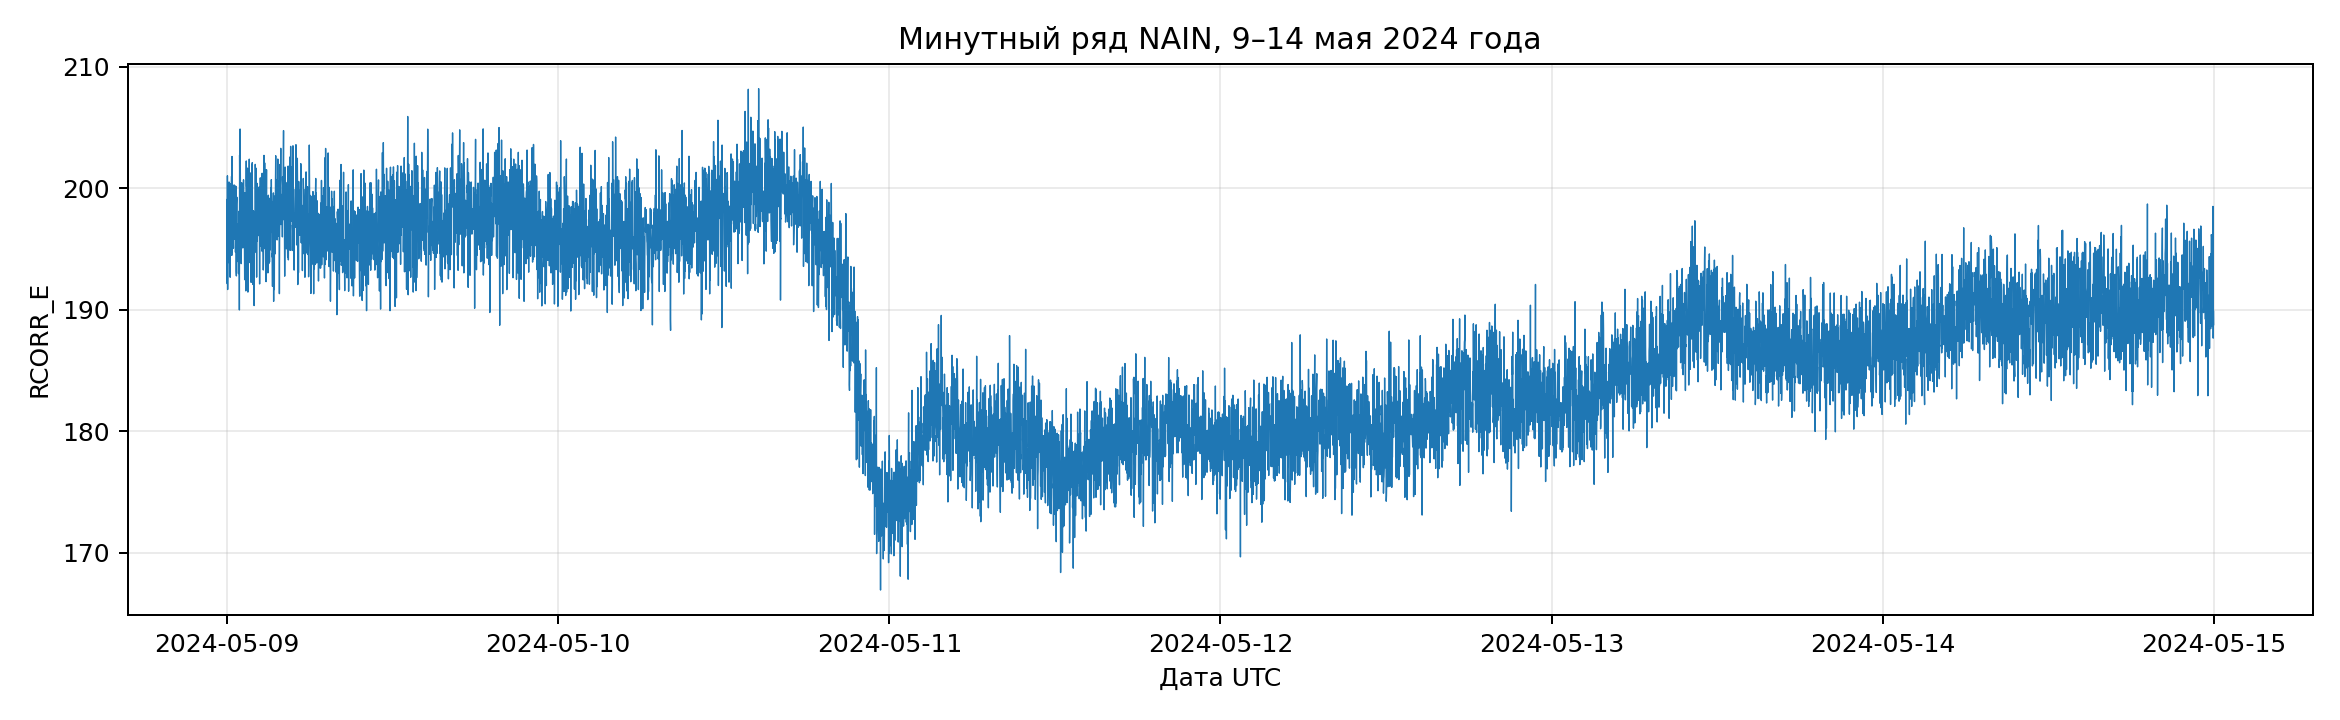

In [17]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display

series = load_signal()
filled = series.interpolate(limit_direction='both')
if filled.isna().any():
    filled = filled.fillna(filled.median())
print('Отсчётов:', len(series))
print('Пропусков до заполнения:', int(series.isna().sum()))
display(filled.head())

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(filled.index, filled, color='tab:blue', linewidth=0.55)
ax.set(title='Минутный ряд NAIN, 9–14 мая 2024 года', xlabel='Дата UTC', ylabel='RCORR_E')
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIG_DIR / 'signal_notebook.png', dpi=180)
display(Image(filename=str(FIG_DIR / 'signal_notebook.png')))


## Расчёт НВП

Комплексный вейвлет Морле, симметричное дополнение на 5760 отсчётов с каждой стороны и 96 частот от 5·10⁻⁶ до 1/240 Гц. Верхняя частота соответствует четырём отсчётам на период. Краевая область зависит от масштаба.


In [18]:
# Не менее четырёх отсчётов на период центральной частоты вейвлета.
frequencies = np.geomspace(5e-6, 1 / (4 * DT), 96)
coefficients, scales = cwt_morlet(filled.to_numpy(float), DT, frequencies, PAD)
power = np.abs(coefficients) ** 2
position = np.arange(len(filled))
distance_to_edge = np.minimum(position, len(filled) - 1 - position)
interior = distance_to_edge >= np.sqrt(2) * scales[:, None]
interior_power = np.where(interior, power, 0.0)
counts = interior.sum(axis=1)
global_power = np.divide(interior_power.sum(axis=1), counts,
                         out=np.full(len(scales), np.nan), where=counts > 0)
dominant_index = int(np.nanargmax(global_power))
dominant_frequency = float(frequencies[dominant_index])
dominant_period_hours = float(1 / dominant_frequency / 3600)
peak = np.unravel_index(int(interior_power.argmax()), interior_power.shape)
peak_frequency = float(frequencies[peak[0]])
peak_time = filled.index[peak[1]]
peak_period_hours = float(1 / peak_frequency / 3600)
print('Размер коэффициентов:', coefficients.shape)
print('Диапазон масштабов:', scales.min(), '—', scales.max())


Размер коэффициентов: (96, 8640)
Диапазон масштабов: 3.819718634205488 — 3183.0988618379065


## Скалограмма


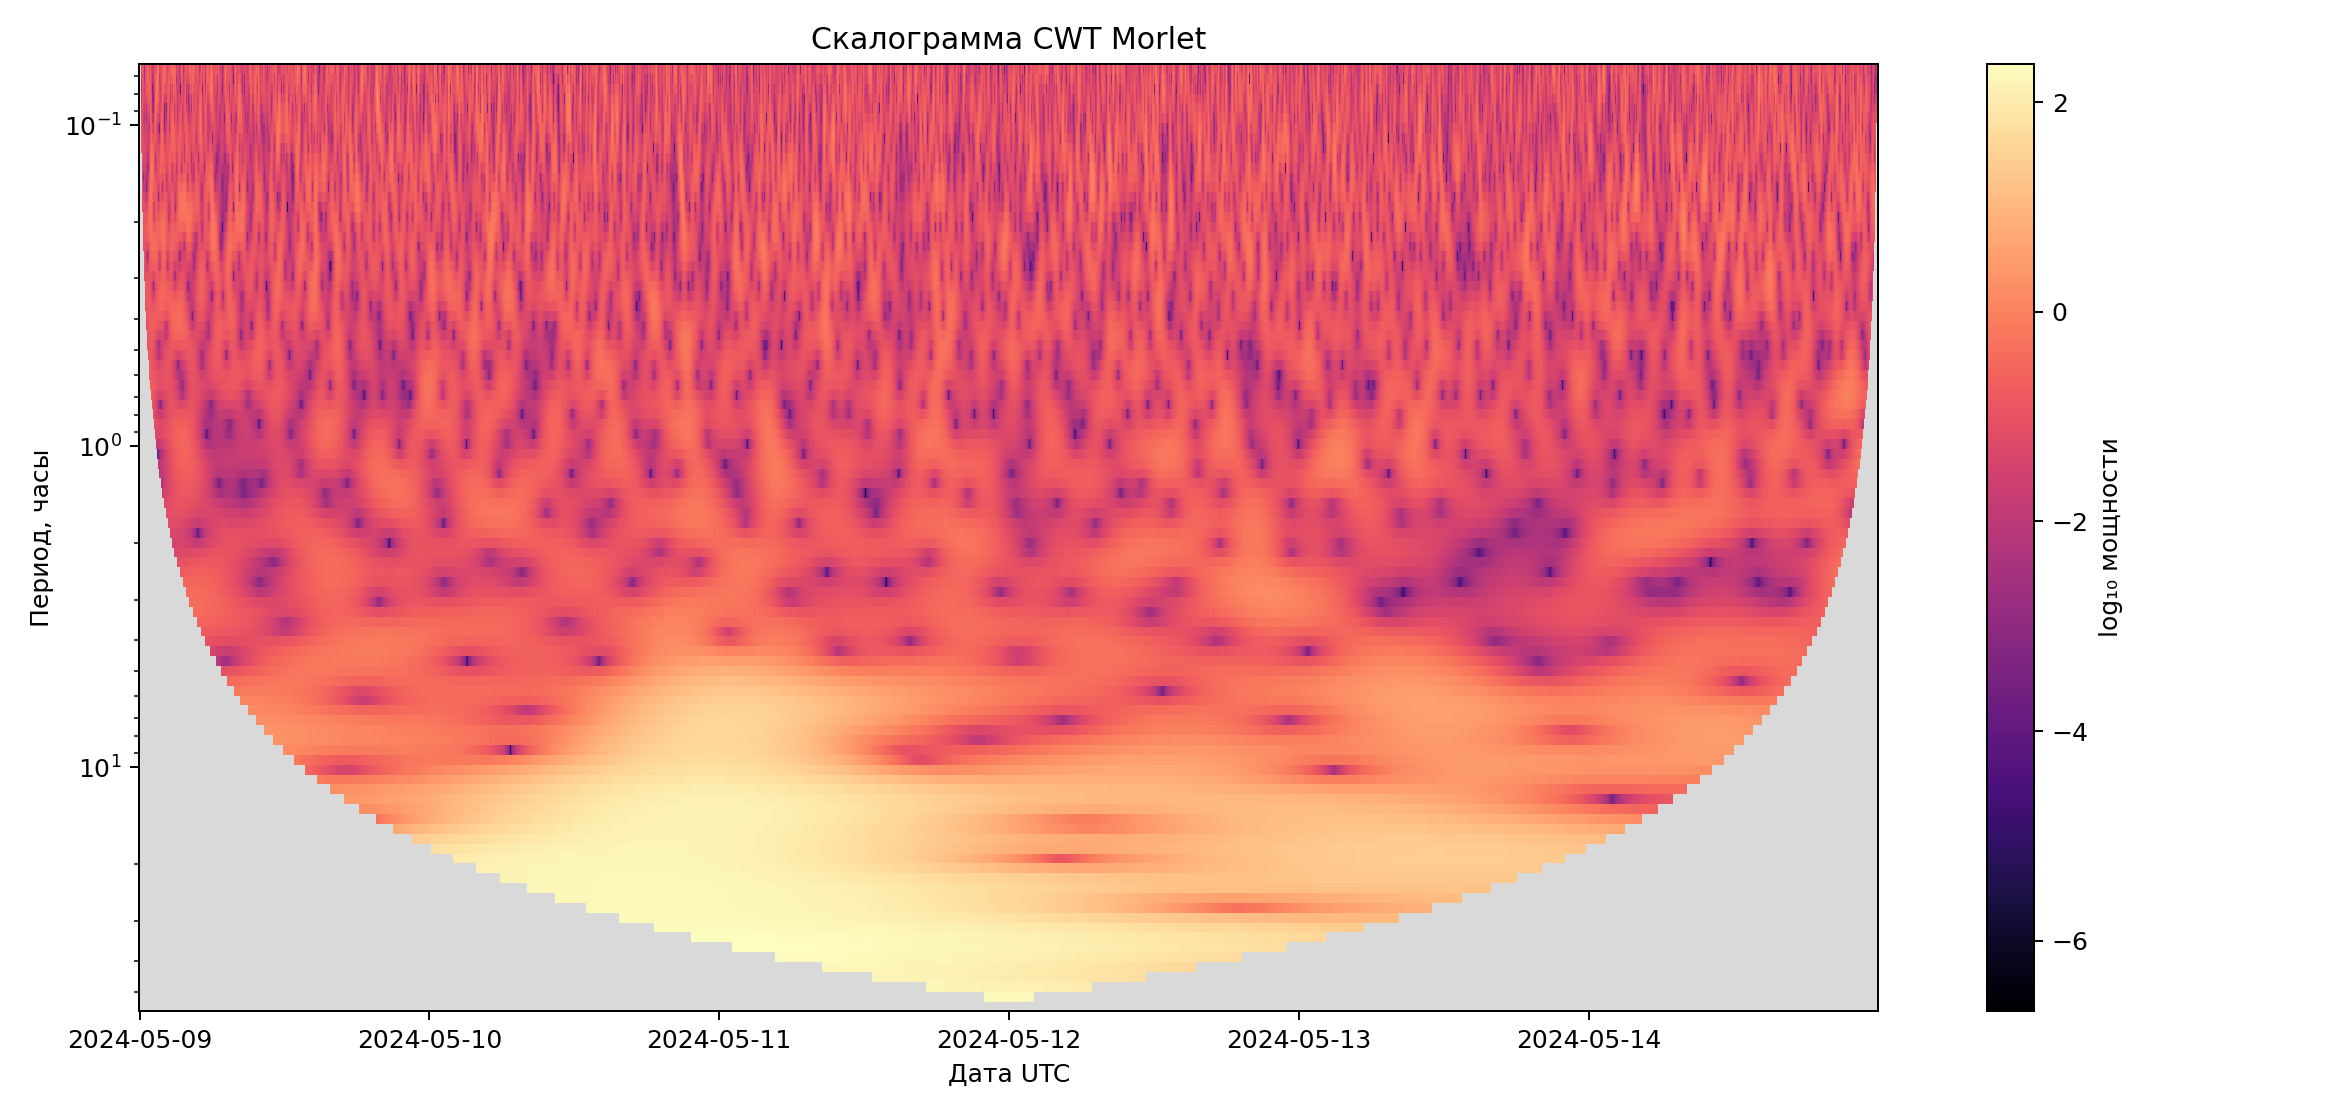

In [19]:
fig, ax = plt.subplots(figsize=(13, 6.2))
visible_power = np.ma.array(np.log10(np.maximum(power, 1e-8)), mask=~interior)
ax.set_facecolor("0.85")
image = ax.pcolormesh(filled.index, 1 / frequencies / 3600, visible_power, shading="auto", cmap="magma")
ax.set_yscale("log")
ax.invert_yaxis()
ax.set(title="Скалограмма CWT Morlet", xlabel="Дата UTC", ylabel="Период, часы")
fig.colorbar(image, ax=ax, label="log₁₀ мощности")
fig.tight_layout()
path = FIG_DIR / "scalogram_notebook.png"
fig.savefig(path, dpi=180)
display(Image(filename=str(path)))
plt.close(fig)



## Средняя мощность по периодам


Максимум средней мощности: 51.76 ч
Локальный максимум: 2024-05-11 01:04:00+00:00, 36.33 ч


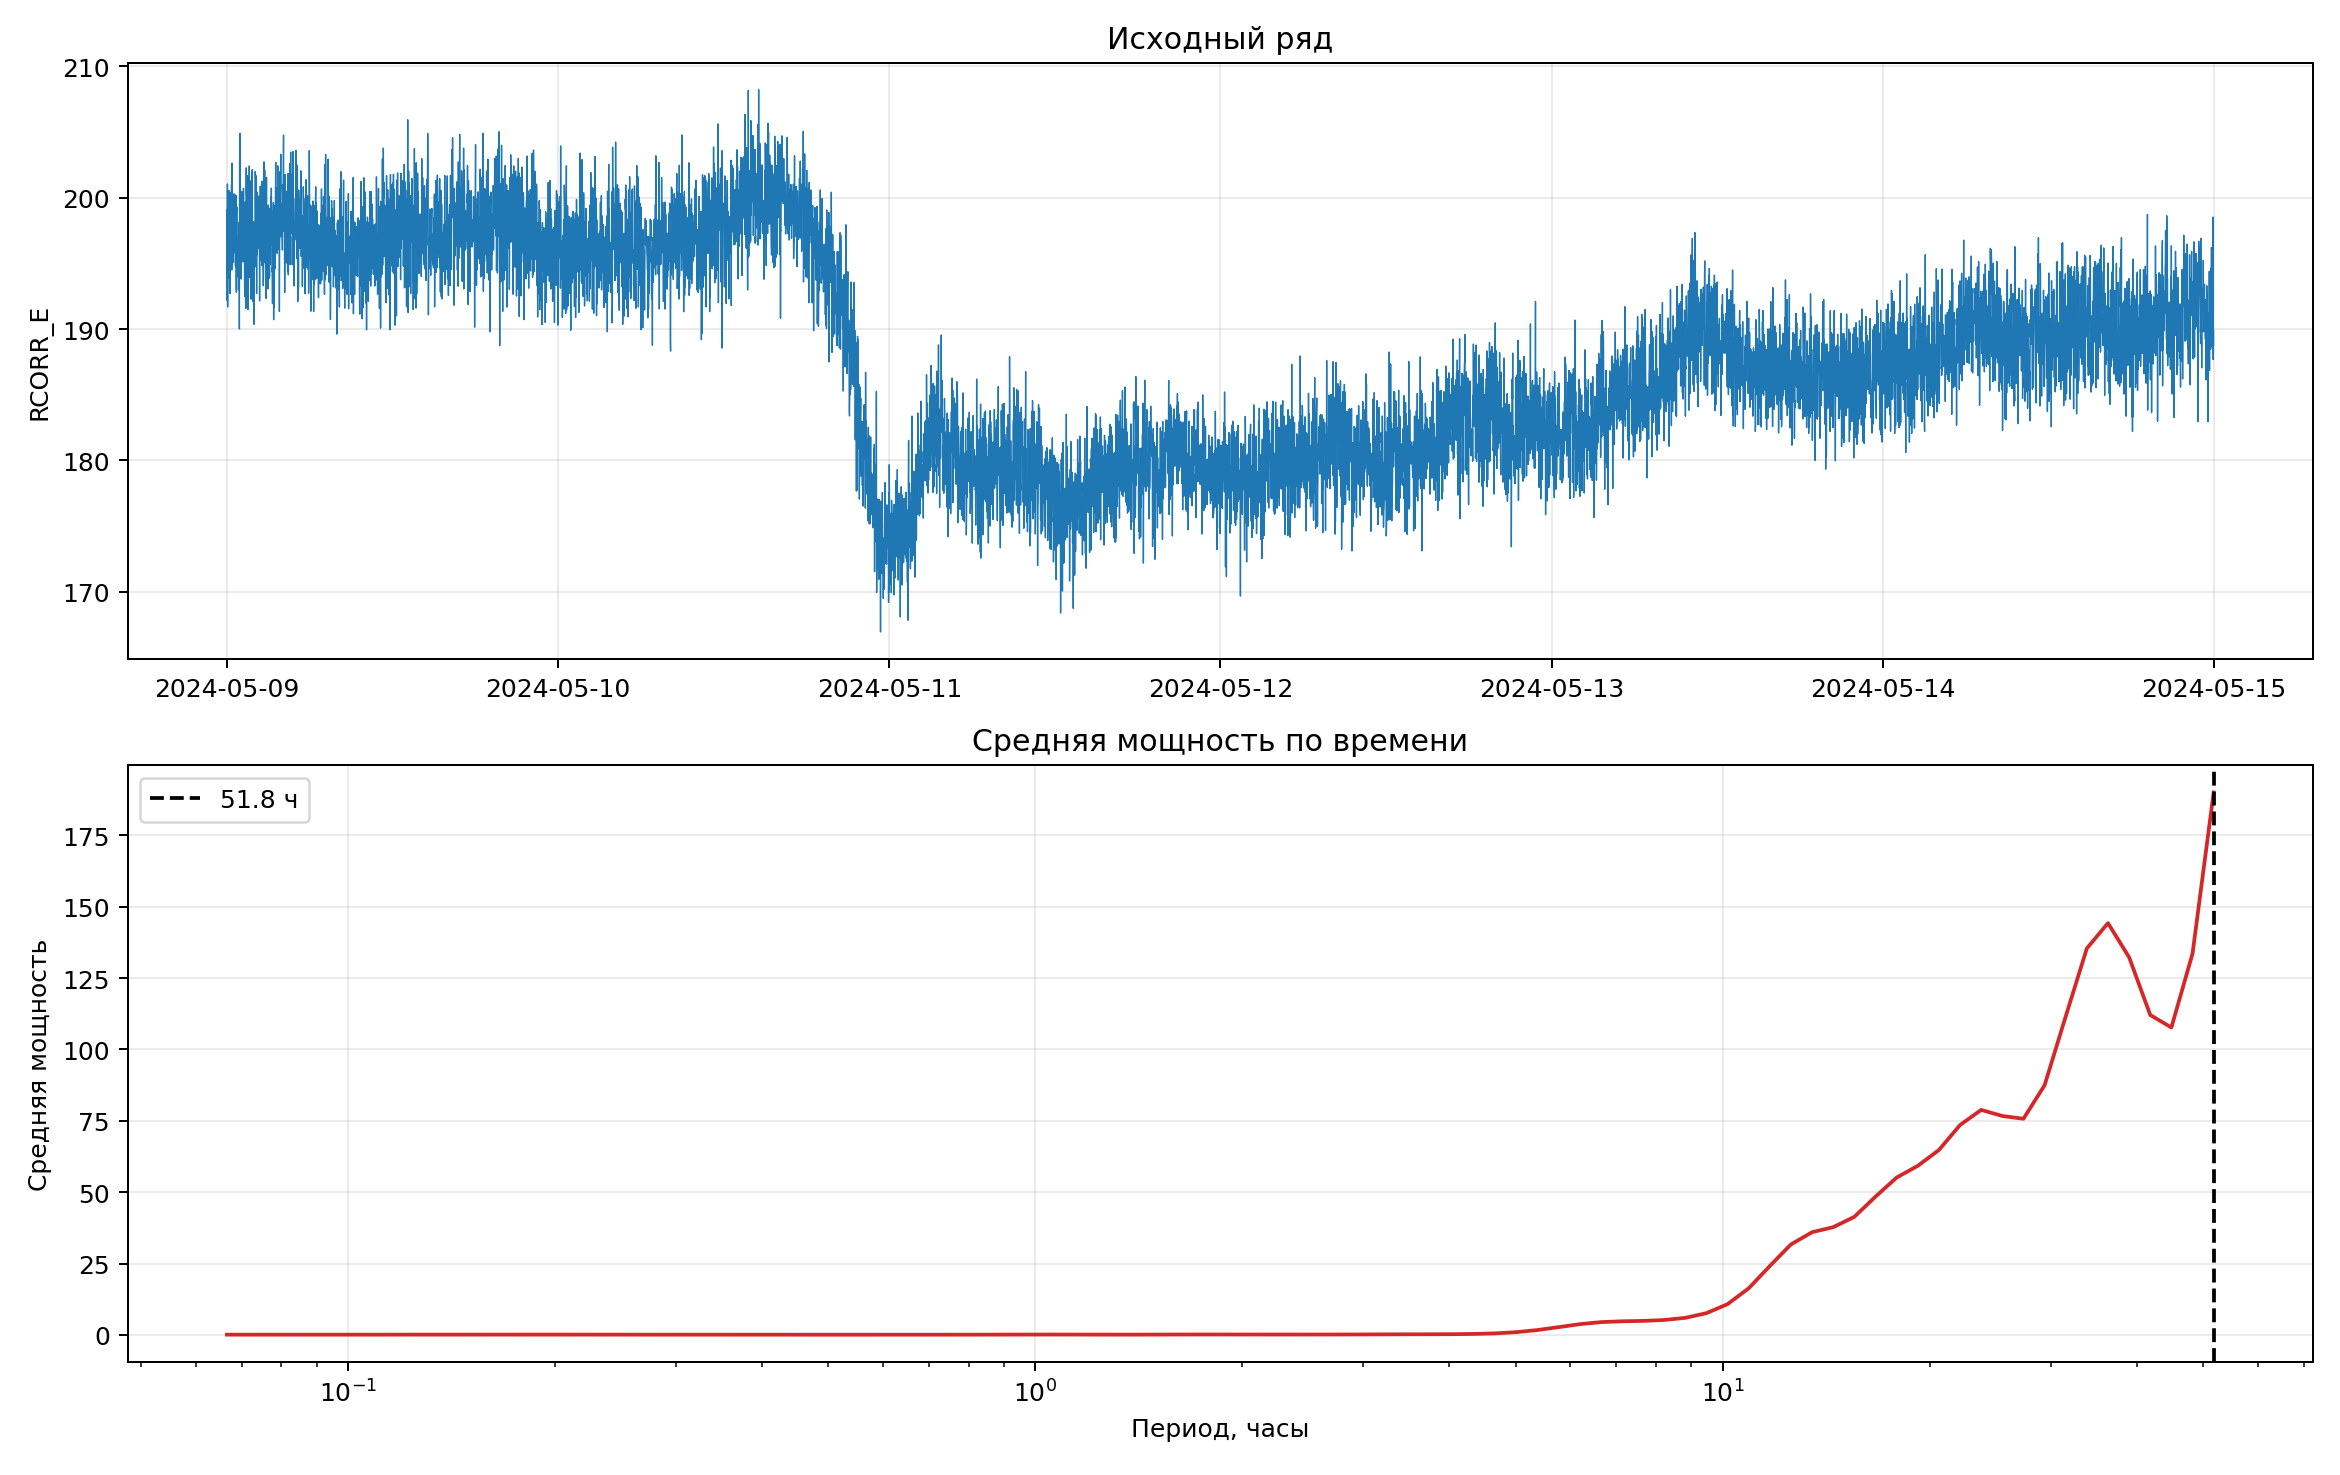

In [20]:
print(f'Максимум средней мощности: {dominant_period_hours:.2f} ч')
print(f'Локальный максимум: {peak_time}, {peak_period_hours:.2f} ч')

fig, axes = plt.subplots(2, 1, figsize=(13, 8.2), sharex=False)
axes[0].plot(filled.index, filled, color="tab:blue", linewidth=0.55)
axes[0].set(title="Исходный ряд", ylabel="RCORR_E")
axes[1].plot(1 / frequencies / 3600, global_power, color="tab:red")
axes[1].axvline(dominant_period_hours, color="black", linestyle="--", label=f"{dominant_period_hours:.1f} ч")
axes[1].set(xscale="log", title="Средняя мощность по времени", xlabel="Период, часы", ylabel="Средняя мощность")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()
path = FIG_DIR / "signal_and_global_power_notebook.png"
fig.savefig(path, dpi=180)
display(Image(filename=str(path)))
plt.close(fig)


## Вейвлет Морле на исходном ряде

Центр волны совпадает с моментом максимального отклика вне краевой области. Фазу берём из комплексного коэффициента в этой точке. Относительная амплитуда волны показана на правой оси.

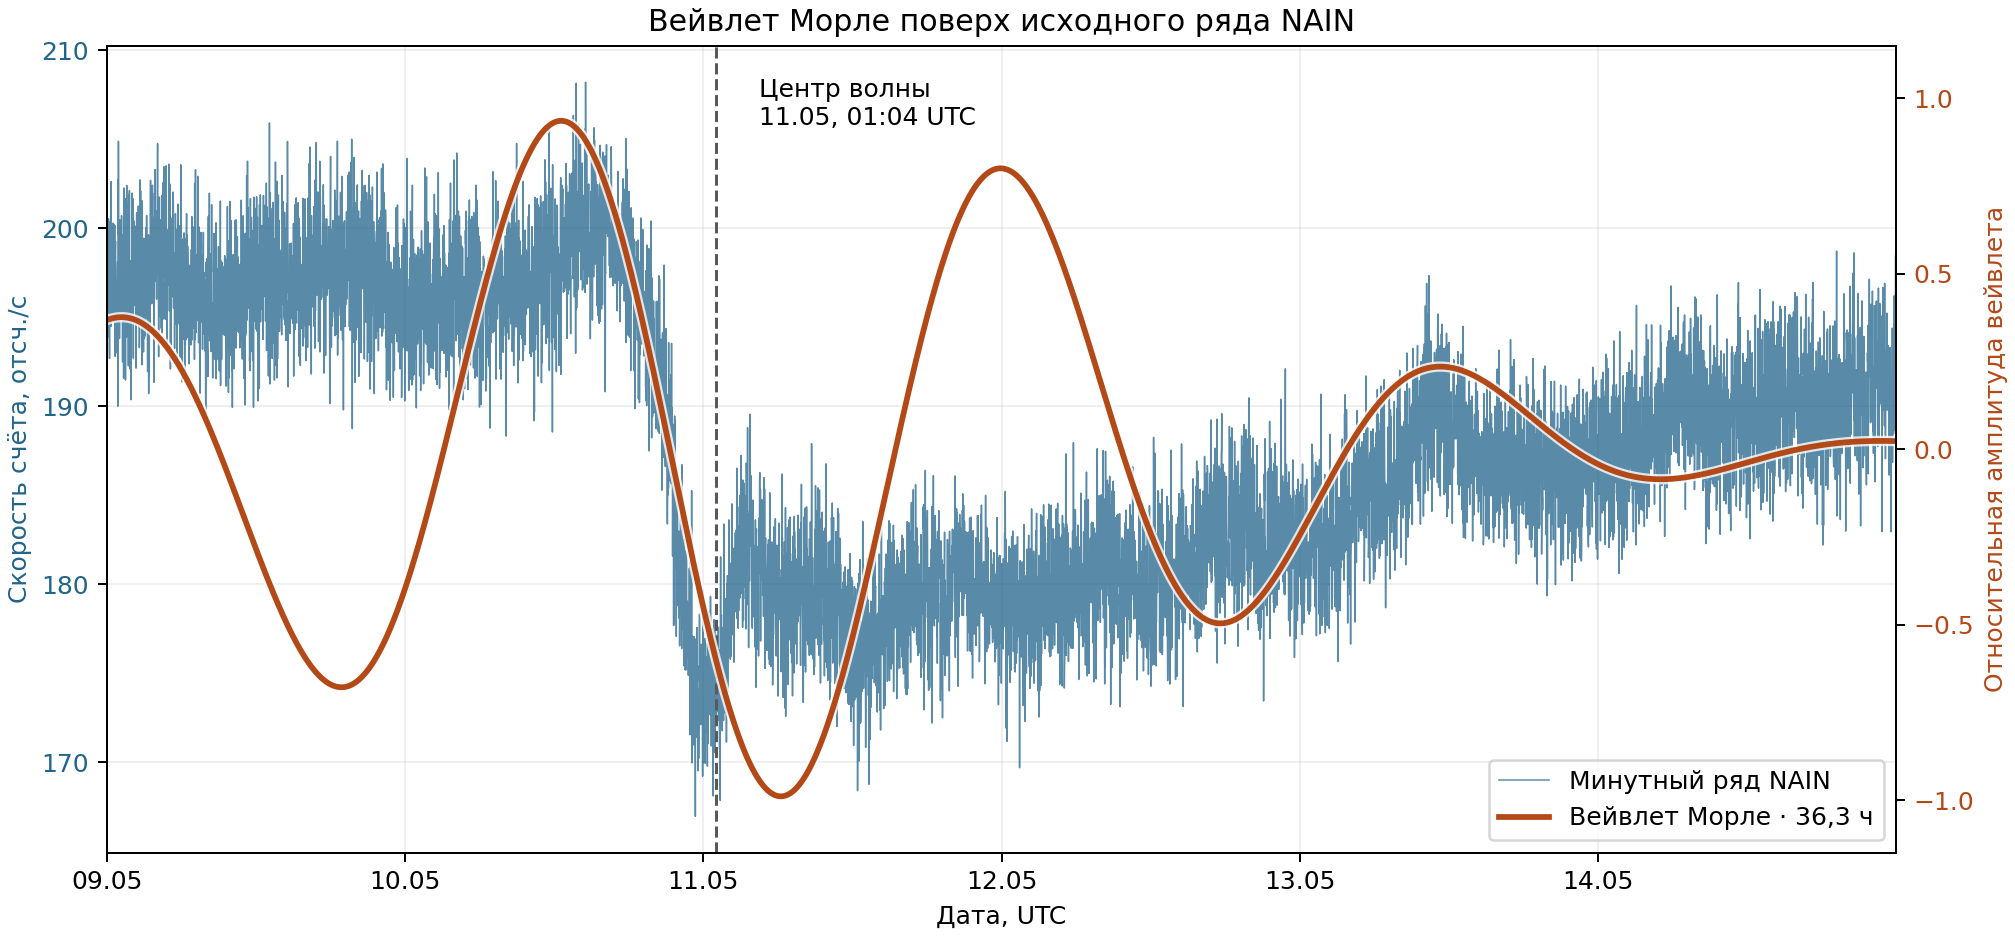

In [21]:
fig = plot_morlet_on_signal(series, peak_time, scales[peak[0]],
                            peak_period_hours, coefficients[peak])
path = FIG_DIR / "morlet_on_signal.png"
fig.savefig(path, dpi=180)
display(Image(filename=str(path)))
plt.close(fig)

## Вывод

Основной локальный максимум приходится на спад 11 мая, а максимум средней мощности находится около двух суток. Оба значения характеризуют этот шестидневный фрагмент.
